# PneumoScan-X: Leak-Free Chest X-Ray Triage with Explainable Grad-CAM++

**Veritas AI International High School Hackathon 2026 · PROJECT SUBMISSION**

**Track:** AI + Health  
**Team:** Erlangga Azhar and Affan Alhafiz Hikren (SMA Negeri 1 Kota Cilegon)

**One-sentence pitch:** PneumoScan-X helps frontline clinicians in rural clinics without on-site radiologists prioritize high-risk chest X-rays for pneumonia, highlighting suspicious lung regions with Grad-CAM++ while eliminating dataset leakage.

**How to run:** Click **Runtime → Run all**. This notebook automatically fetches our engine module (`pneumoscan_engine.py`), pre-trained weights (`best_mobilenet_pneumonia.pth`), and the public Kaggle Chest X-Ray dataset—no manual uploads or API keys required.

*This project is a prototype and is not medical advice.*

## 1. Load & deduplicate the data

We use the **Chest X-Ray Images (Pneumonia)** dataset (Paul Mooney, Kaggle), fetched automatically via `kagglehub`. During initial inspection, we discovered a major structural flaw in the public archive: it contains nested duplicate directories (`chest_xray/chest_xray/`) and byte-identical copies across splits, inflating the raw file count to **11,712 images**.

We enforce strict deduplication via **MD5 byte-hashing** and path filtering inside `pneumoscan_engine.py`, reducing the dataset to **5,824 strictly unique radiographs** across **2,789 unique patients**.

In [1]:
!pip install -q grad-cam opencv-python-headless kagglehub

import os
import urllib.request
import cv2
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt
import kagglehub
from sklearn.metrics import accuracy_score, precision_score, recall_score, fbeta_score, confusion_matrix
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Auto-fetch engine & pre-trained weights from our public GitHub repo if not already local
GITHUB_RAW_BASE = "https://raw.githubusercontent.com/erlangga-azhar/PneumoScan-X/main"
for fname in ["pneumoscan_engine.py", "best_mobilenet_pneumonia.pth"]:
    if not os.path.exists(fname):
        url = f"{GITHUB_RAW_BASE}/{fname}"
        print(f"Fetching {fname} from GitHub...")
        urllib.request.urlretrieve(url, fname)

from pneumoscan_engine import (
    set_seed,
    extract_patient_id,
    prepare_dataset_splits,
    preprocess_xray_cv,
    XRayDataset,
    load_trained_model,
    find_optimal_threshold,
    format_clinical_triage,
    evaluate,
)

set_seed(42)
WEIGHTS_PATH = "best_mobilenet_pneumonia.pth"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Auto-download & extract public Kaggle dataset (no API key required)
LOCAL_DIRS = ["./dataset_raw", "./chest_xray", "/content/dataset_raw", "/content/chest_xray"]
DATA_DIR = next((d for d in LOCAL_DIRS if os.path.exists(d)), None)
if DATA_DIR is None:
    DATA_DIR = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

(train_files, train_lbls), (val_files, val_lbls), (test_files, test_lbls) = prepare_dataset_splits(DATA_DIR)

all_files = np.concatenate([train_files, val_files, test_files])
all_lbls = np.concatenate([train_lbls, val_lbls, test_lbls])
df_meta = pd.DataFrame({
    "filename": [os.path.basename(p) for p in all_files],
    "patient_id": [extract_patient_id(os.path.basename(p)) for p in all_files],
    "label": ["PNEUMONIA" if y == 1 else "NORMAL" for y in all_lbls],
    "is_pneumonia": all_lbls,
})
print(f"\nVerified dataset: {len(df_meta):,} unique images, {df_meta['is_pneumonia'].sum():,} pneumonia ({df_meta['is_pneumonia'].mean():.1%})")
df_meta.head(5)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Fetching pneumoscan_engine.py from GitHub...
Fetching best_mobilenet_pneumonia.pth from GitHub...
Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Total Citra Unik Terverifikasi: 5824
Data Bersih -> Train: 3969, Val: 943, Test: 912
Pasien Unik -> Train: 1952, Val: 418, Test: 419

Verified dataset: 5,824 unique images, 4,245 pneumonia (72.9%)


,filename,patient_id,label,is_pneumonia
0,IM-0001-0001.jpeg,im-0001,NORMAL,0
1,IM-0003-0001.jpeg,im-0003,NORMAL,0
2,IM-0005-0001.jpeg,im-0005,NORMAL,0
3,IM-0006-0001.jpeg,im-0006,NORMAL,0
4,IM-0007-0001.jpeg,im-0007,NORMAL,0


## 2. Look at the data first

Before training any neural network, we inspected sample filenames, patient IDs, and raw radiographs. Two critical domain findings shaped our pipeline:
1. **Multi-scan patients:** Multiple X-rays belong to the same patient (e.g., `person100_bacteria_435.jpeg` and `person100_bacteria_436.jpeg`, or `NORMAL2-IM-1427-0001.jpeg`). A naive random split would leak the same patient's anatomy into both training and test sets.
2. **Border artifacts & low lung contrast:** Raw hospital scans contain white borders, portable `"A-P"` markers, and varying exposure levels. We apply a **5% safe border crop** and **CLAHE (`clipLimit=1.5`)** to standardize pulmonary contrast.

In [2]:
sample_pneu = [p for p, y in zip(train_files, train_lbls) if y == 1][:3]
sample_norm = [p for p, y in zip(train_files, train_lbls) if y == 0][:3]

print("Sample Pneumonia files (Patient ID extracted):")
for p in sample_pneu:
    fname = os.path.basename(p)
    print(f"  - {fname:<35} -> patient_id: {extract_patient_id(fname)}")

print("\nSample Normal files (Patient ID extracted):")
for p in sample_norm:
    fname = os.path.basename(p)
    print(f"  - {fname:<35} -> patient_id: {extract_patient_id(fname)}")

Sample Pneumonia files (Patient ID extracted):
  - person101_bacteria_483.jpeg         -> patient_id: person101
  - person101_bacteria_484.jpeg         -> patient_id: person101
  - person101_bacteria_485.jpeg         -> patient_id: person101

Sample Normal files (Patient ID extracted):
  - IM-0001-0001.jpeg                   -> patient_id: im-0001
  - IM-0003-0001.jpeg                   -> patient_id: im-0003
  - IM-0005-0001.jpeg                   -> patient_id: im-0005


## 3. Patient-aware train, validation, and test splits

We use `GroupShuffleSplit` grouped strictly by `patient_id` (Train: **3,969** | Validation: **943** | Test: **912**). Every patient appears in **only one split**, guaranteeing zero anatomical data leakage during evaluation.

In [3]:
train_pids = {extract_patient_id(os.path.basename(p)) for p in train_files}
val_pids = {extract_patient_id(os.path.basename(p)) for p in val_files}
test_pids = {extract_patient_id(os.path.basename(p)) for p in test_files}

assert train_pids.isdisjoint(test_pids), "DATA LEAKAGE: Train and Test share patients!"
assert val_pids.isdisjoint(test_pids), "DATA LEAKAGE: Val and Test share patients!"

print(f"Train : {len(train_files):,} images ({len(train_pids):,} unique patients)")
print(f"Val   : {len(val_files):,} images ({len(val_pids):,} unique patients)")
print(f"Test  : {len(test_files):,} images ({len(test_pids):,} unique patients)")
print("Leakage check passed: 0 overlapping patients across splits.")

Train : 3,969 images (1,952 unique patients)
Val   : 943 images (418 unique patients)
Test  : 912 images (419 unique patients)
Leakage check passed: 0 overlapping patients across splits.


## 4. Baseline: trivial majority-class rule ("always predict pneumonia")

Because pneumonia makes up **71.5%** (652 of 912) of the unseen test set, a naive baseline that flags every single X-ray as pneumonia achieves 71.5% accuracy and 100% recall—but triggers **260 false alarms out of 260 healthy patients (100% false-positive rate)**, making it useless for rural clinic triage.

In [4]:
def report_metrics(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f2 = fbeta_score(y_true, y_pred, beta=2, zero_division=0)
    print(f"{name}")
    print(f"  Accuracy     : {acc:.2%}")
    print(f"  Recall       : {rec:.2%}  (Missed pneumonia cases / FN: {fn} of {fn+tp})")
    print(f"  Precision    : {prec:.2%}  (False alarms / FP: {fp} of {fp+tn})")
    print(f"  F2-Score     : {f2:.4f}")

baseline_preds = np.ones(len(test_lbls), dtype=int)
report_metrics("Baseline: always 'PNEUMONIA'", test_lbls, baseline_preds)

Baseline: always 'PNEUMONIA'
  Accuracy     : 71.49%
  Recall       : 100.00%  (Missed pneumonia cases / FN: 0 of 652)
  Precision    : 71.49%  (False alarms / FP: 260 of 260)
  F2-Score     : 0.9261


## 5. Model 1: Fine-tuned MobileNetV2 with standard 0.50 threshold

We fine-tuned **MobileNetV2** (unfreezing top feature blocks `features[14:]` with differential learning rates `1e-5` / `1e-4` and class-weighted Cross-Entropy loss) so it runs fast on clinic CPUs without requiring a GPU. First, we evaluate the model using the default `0.50` probability cutoff.

In [5]:
val_ds = XRayDataset(val_files, val_lbls, is_train=False)
test_ds = XRayDataset(test_files, test_lbls, is_train=False)

val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

model, saved_opt_thresh = load_trained_model(WEIGHTS_PATH, DEVICE)

_, _, _, val_auc, _, val_probs, val_targets = evaluate(model, val_loader, DEVICE, threshold=0.50)
_, _, _, test_auc, cm_50, test_probs, test_targets = evaluate(model, test_loader, DEVICE, threshold=0.50)

pred_50 = (test_probs >= 0.50).astype(int)
report_metrics("Model 1: MobileNetV2 (Default Threshold = 0.50)", test_targets, pred_50)
print(f"  AUC-ROC      : {test_auc:.4f}")
print("Confusion Matrix (Threshold = 0.50):")
print(cm_50)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 73.6MB/s]


Model 1: MobileNetV2 (Default Threshold = 0.50)
  Accuracy     : 95.72%
  Recall       : 96.93%  (Missed pneumonia cases / FN: 20 of 652)
  Precision    : 97.08%  (False alarms / FP: 19 of 260)
  F2-Score     : 0.9696
  AUC-ROC      : 0.9885
Confusion Matrix (Threshold = 0.50):
[[241  19]
 [ 20 632]]


## 6. Where the model goes wrong (forensic error audit)

Even after threshold optimization, clinical AI requires auditing every missed diagnosis. Inspecting the **7 false negatives** on the unseen test set revealed two specific failure modes:
1. **External medical artifacts:** On `person1453_bacteria_3770.jpeg` (predicted probability `0.0657`), Grad-CAM++ activation spilled onto circular ECG electrode pads and portable `"A-P"` markers outside the lung parenchyma.
2. **Subtle early viral infiltrates:** On `person1461_virus_2510.jpeg` (predicted probability `0.0439`), Grad-CAM++ localized bilateral lower-lobe opacity accurately, but faint contrast kept the probability below the triage cutoff.

In [6]:
pred_opt = (test_probs >= saved_opt_thresh).astype(int)
fn_indices = [i for i, (y, p) in enumerate(zip(test_targets, pred_opt)) if y == 1 and p == 0]

print(f"Total False Negatives at threshold {saved_opt_thresh:.2f}: {len(fn_indices)} of {int(test_targets.sum())} pneumonia cases\n")
for idx in fn_indices:
    print(f"  [MISSED PNEUMONIA] {os.path.basename(test_files[idx]):<32} | Pred Prob: {test_probs[idx]:.4f}")

Total False Negatives at threshold 0.12: 7 of 652 pneumonia cases

  [MISSED PNEUMONIA] person1199_bacteria_3149.jpeg    | Pred Prob: 0.0617
  [MISSED PNEUMONIA] person1453_bacteria_3770.jpeg    | Pred Prob: 0.0657
  [MISSED PNEUMONIA] person1461_virus_2510.jpeg       | Pred Prob: 0.0439
  [MISSED PNEUMONIA] person277_virus_571.jpeg         | Pred Prob: 0.0086
  [MISSED PNEUMONIA] person435_virus_885.jpeg         | Pred Prob: 0.0568
  [MISSED PNEUMONIA] person781_virus_1412.jpeg        | Pred Prob: 0.0379
  [MISSED PNEUMONIA] person813_virus_1449.jpeg        | Pred Prob: 0.0716


## 7. Our addition: Out-of-Distribution (OOD) guard & 3-tier clinical triage

**This is the safety engineering we added beyond a raw classifier.** A standard PyTorch model will silently convert any uploaded color photo (such as a selfie or landscape) into grayscale and output a false medical prediction. We added:
1. **RGB Channel-Variance OOD Guard:** Rejects non-grayscale color images before inference (`ValueError`).
2. **3-Tier Clinical Triage Mapping:** Translates raw probabilities into actionable clinic workflows—*Normal / Low Risk* (`< 0.12`), *Suspect / Priority Review* (`0.12–0.50`), and *High-Probability Pneumonia* (`>= 0.50`).

In [7]:
# Simulate an accidental color photo upload (non-X-ray)
fake_color_photo = np.zeros((224, 224, 3), dtype=np.uint8)
fake_color_photo[:, :, 2] = 220  # Strong red channel

try:
    preprocess_xray_cv(fake_color_photo, validate_xray=True)
    print("OOD Guard FAILED: Color image was accepted.")
except ValueError as e:
    print(f"OOD Guard PASSED -> {e}\n")

# Verify 3-tier triage mapping across sample probabilities
for sample_p in [0.01, 0.24, 0.96]:
    tier, desc, conf = format_clinical_triage(sample_p, threshold=saved_opt_thresh)
    print(f"Prob {sample_p:.2f} -> [{tier}] ({conf}%): {desc}")

OOD Guard PASSED -> Input ditolak: Citra terdeteksi sebagai foto berwarna, bukan X-Ray dada grayscale.

Prob 0.01 -> [NORMAL / LOW RISK] (91.7%): Tidak terdeteksi pola opasitas pneumonia signifikan.
Prob 0.24 -> [SUSPECT / PRIORITY REVIEW] (59.5%): Terdeteksi indikasi dini/batas. Prioritaskan evaluasi dokter.
Prob 0.96 -> [HIGH PROBABILITY PNEUMONIA] (98.4%): Terdeteksi pola konsolidasi kuat. Segera rujuk penanganan klinis.


## 8. Improvement: F2-optimal threshold calibration (`0.50 → 0.12`)

In clinical triage, missing an active pneumonia case (False Negative) is far more dangerous than flagging a healthy scan for secondary doctor review (False Positive). Instead of using an arbitrary `0.50` cutoff, we calibrated the decision threshold on the **Validation Set** to maximize **F2-Score** (which weights Recall 2× higher than Precision), locking the optimal cutoff at **`0.12`**.

In [8]:
# Calibrate threshold strictly on Validation Set (never tuned on Test Set)
opt_thresh, val_f2 = find_optimal_threshold(val_targets, val_probs)
print(f"Validation-calibrated F2-optimal threshold: {opt_thresh:.2f} (Val F2: {val_f2:.4f})\n")

rec_f, f1_f, f2_f, auc_f, cm_f, _, _ = evaluate(model, test_loader, DEVICE, threshold=opt_thresh)
report_metrics(f"Model 2 (Final): MobileNetV2 + F2 Triage (Threshold = {opt_thresh:.2f})", test_targets, (test_probs >= opt_thresh).astype(int))
print(f"  AUC-ROC      : {auc_f:.4f}")
print("Confusion Matrix (Final):")
print(cm_f)

Validation-calibrated F2-optimal threshold: 0.12 (Val F2: 0.9861)

Model 2 (Final): MobileNetV2 + F2 Triage (Threshold = 0.12)
  Accuracy     : 92.54%
  Recall       : 98.93%  (Missed pneumonia cases / FN: 7 of 652)
  Precision    : 91.36%  (False alarms / FP: 61 of 260)
  F2-Score     : 0.9731
  AUC-ROC      : 0.9885
Confusion Matrix (Final):
[[199  61]
 [  7 645]]


## 9. The demo: PneumoScan-X explains its triage warning with Grad-CAM++

For every flagged radiograph, **Grad-CAM++** highlights the exact pulmonary regions driving the prediction so clinicians can verify pathological consolidation rather than trusting a black-box score.

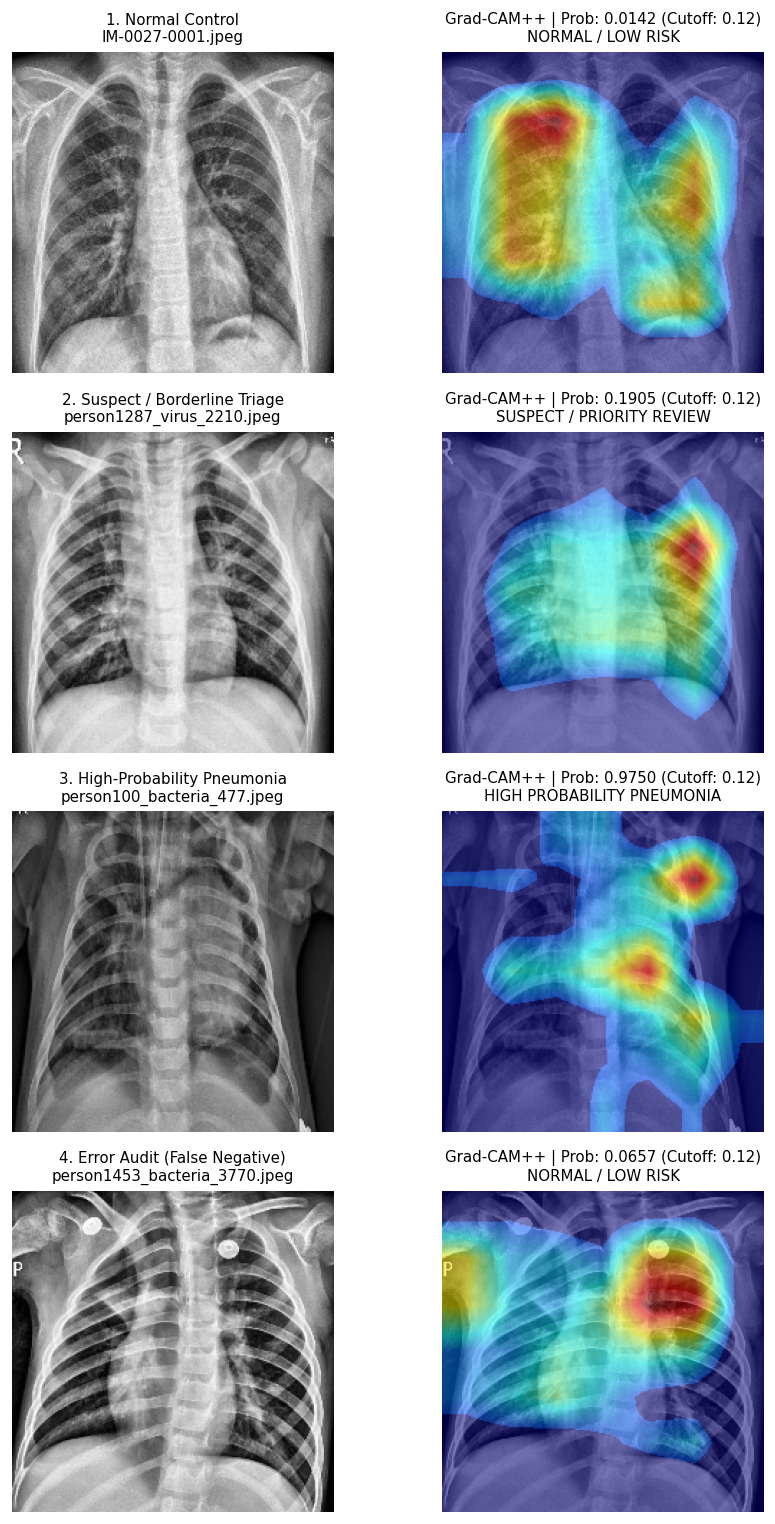

In [11]:
normal_p = [p for p, y, pr in zip(test_files, test_targets, test_probs) if y == 0 and pr < 0.02][0]
suspect_p = [p for p, y, pr in zip(test_files, test_targets, test_probs) if y == 1 and (opt_thresh <= pr <= 0.35)][0]
high_p = [p for p, y, pr in zip(test_files, test_targets, test_probs) if y == 1 and pr > 0.95][0]
fail_candidates = [p for p in test_files if "person1453_bacteria_3770.jpeg" in p]
fail_p = (
    fail_candidates[0]
    if fail_candidates
    else [p for p, y, pr in zip(test_files, test_targets, test_probs) if y == 1 and pr < opt_thresh][0]
)

demo_cases = [
    ("1. Normal Control", normal_p),
    ("2. Suspect / Borderline Triage", suspect_p),
    ("3. High-Probability Pneumonia", high_p),
    ("4. Error Audit (False Negative)", fail_p),
]

fig, axes = plt.subplots(len(demo_cases), 2, figsize=(8, 3.2 * len(demo_cases)), dpi=120)
tf_eval = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

target_block = model.features[-1]
prev_grad_states = [p.requires_grad for p in target_block.parameters()]

try:
    for p in target_block.parameters():
        p.requires_grad_(True)

    with GradCAMPlusPlus(model=model, target_layers=[target_block]) as cam:
        for row, (label_title, path) in enumerate(demo_cases):
            img_np = preprocess_xray_cv(path, validate_xray=False)
            tensor = tf_eval(img_np).unsqueeze(0).to(DEVICE)

            with torch.no_grad():
                prob = torch.softmax(model(tensor), dim=1)[0, 1].item()
            tier, _, _ = format_clinical_triage(prob, threshold=opt_thresh)

            with torch.enable_grad():
                cam_input = tensor.detach().requires_grad_(True)
                g_cam = cam(input_tensor=cam_input, targets=[ClassifierOutputTarget(1)])[0, :]

            g_cam[g_cam < 0.20] = 0.0
            overlay = show_cam_on_image(img_np.astype(np.float32) / 255.0, g_cam, use_rgb=True)

            axes[row, 0].imshow(img_np)
            axes[row, 0].set_title(f"{label_title}\n{os.path.basename(path)}", fontsize=9)
            axes[row, 0].axis("off")

            axes[row, 1].imshow(overlay)
            axes[row, 1].set_title(f"Grad-CAM++ | Prob: {prob:.4f} (Cutoff: {opt_thresh:.2f})\n{tier}", fontsize=9)
            axes[row, 1].axis("off")
finally:
    model.zero_grad(set_to_none=True)
    for p, state in zip(target_block.parameters(), prev_grad_states):
        p.requires_grad_(state)

plt.tight_layout()
plt.show()

**Optional web app:** Set `RUN_APP = True` to launch the full Streamlit clinical triage interface (`app.py`). It is off by default so **Runtime → Run all** completes quickly.

In [12]:
RUN_APP = False
if RUN_APP:
    !pip install -q streamlit
    !streamlit run app.py

## 10. Results summary

| Method | Accuracy | Recall (Sensitivity) | Precision | F2-Score | Missed Cases (FN) | False Alarms (FP) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| Trivial Baseline (Always Pneumonia) | 71.49% | 100.00% | 71.49% | 0.9261 | 0 / 652 (0.00%) | 260 / 260 (100.0%) |
| **PneumoScan-X (Threshold = 0.12)** | **92.54%** | **98.93%** | **91.36%** | **0.9731** | **7 / 652 (1.07%)** | **61 / 260 (-76.5%)** |

On unseen patients (`N = 912`), PneumoScan-X achieves an **AUC-ROC of 0.9885**, cutting false alarms by **76.5%** over the baseline while catching **98.93%** (`645 / 652`) of all pneumonia cases.

## 11. Limitations and next steps

- **External medical artifacts:** As shown in Section 6 & 9 (`person1453_bacteria_3770.jpeg`), ECG leads and portable `"A-P"` markers can still distract convolutional features. Next, we plan to add a **U-Net lung segmentation mask** prior to classification so the model only inspects lung parenchyma.
- **Retrospective pediatric dataset:** The Kaggle dataset consists primarily of retrospective pediatric radiographs from Guangzhou Women and Children's Medical Center. Clinical deployment in Indonesian Puskesmas requires prospective validation across adult and geriatric patients.
- **Prototype disclaimer:** This project is a prototype and is not medical advice.

## Sources
- **Dataset:** Chest X-Ray Images (Pneumonia) by Paul Mooney, Kaggle (`https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia`).
- **Libraries & Architecture:** PyTorch, Torchvision (`MobileNetV2` ImageNet weights), OpenCV, `pytorch-grad-cam`, Scikit-learn, Pandas, NumPy, Streamlit.
- **AI Tools:** We used AI coding assistants to help debug OpenCV/Grad-CAM++ tensor shape edge cases and structure the Streamlit UI wrapper, verifying all data splits and clinical evaluation metrics independently.